Number of matched observations: 7769


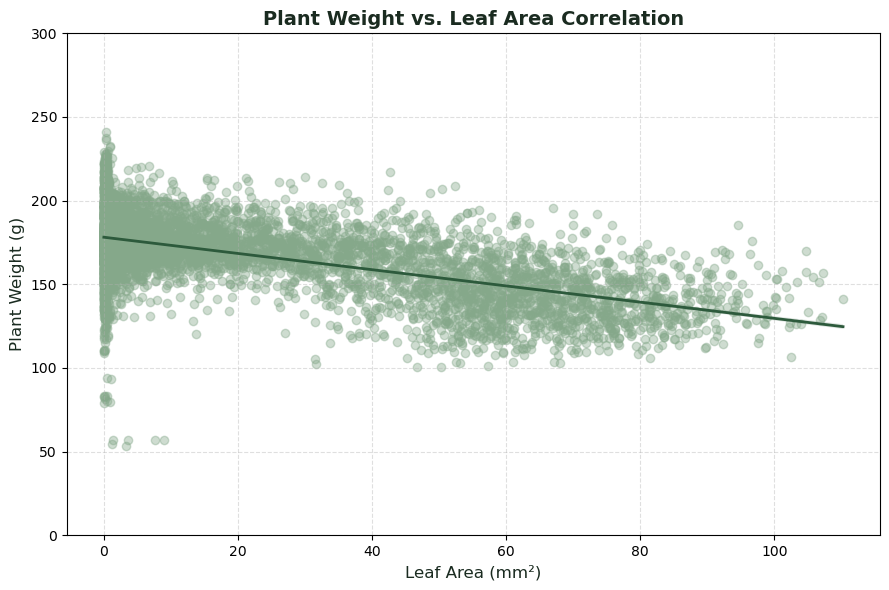

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df_weights = pd.read_csv('plant-weights.csv')
df_rgb2 = pd.read_csv('rgb2-features.csv')

# Convert dates
df_weights['date_clean'] = pd.to_datetime(df_weights['date']).dt.normalize()
df_rgb2['date_clean'] = pd.to_datetime(df_rgb2['date']).dt.normalize()

# Remove missing values from RGB data
df_rgb2 = df_rgb2.dropna(subset=['area_mm2'])

# Optional: remove zero-area observations
df_rgb2 = df_rgb2[df_rgb2['area_mm2'] > 0]

# Aggregate RGB measurements to one value per plant/day
rgb_daily = (
    df_rgb2.groupby(['plant_id', 'date_clean'], as_index=False)
           .agg(area_mm2=('area_mm2', 'mean'))
)

# Aggregate weight measurements to one value per plant/day
weight_daily = (
    df_weights.groupby(['plant_id', 'date_clean'], as_index=False)
              .agg(weight_g=('weight_g', 'mean'))
)

# Merge
merged = pd.merge(
    weight_daily,
    rgb_daily,
    on=['plant_id', 'date_clean'],
    how='inner'
)

# Final cleanup
valid_data = merged.dropna(subset=['weight_g', 'area_mm2'])
print(f"Number of matched observations: {len(valid_data)}")

# Plot with presentation color scheme
plt.figure(figsize=(9, 6))

# Define matching colors from your slides
forest_green = '#2D5A3C'
sage_green = '#85A88A'

sns.regplot(
    data=valid_data,
    x='area_mm2',
    y='weight_g',
    scatter_kws={'alpha': 0.4, 'color': sage_green},
    line_kws={'color': forest_green, 'linewidth': 2}
)

plt.title('Plant Weight vs. Leaf Area Correlation', fontsize=14, fontweight='bold', color='#1A2B20')
plt.xlabel('Leaf Area (mm²)', fontsize=12, color='#1A2B20')
plt.ylabel('Plant Weight (g)', fontsize=12, color='#1A2B20')

# Adjust if your weights exceed 300 g
plt.ylim(0, 300)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()

plt.savefig('plant_weight_vs_leaf_area_limit300.png', dpi=300)
plt.show()

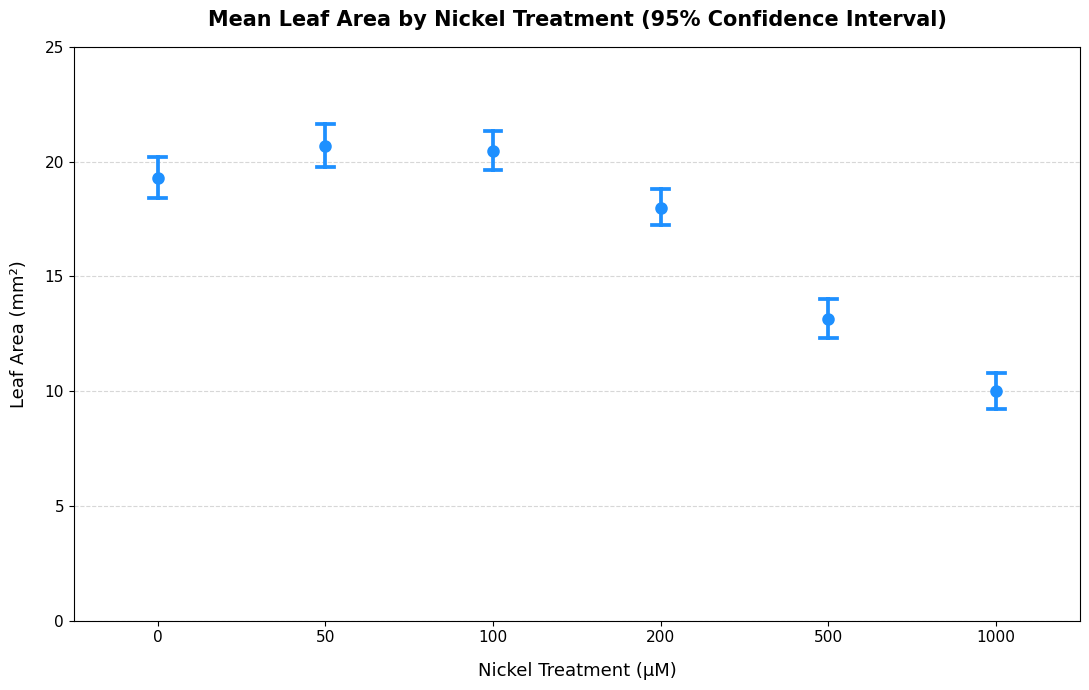

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the design and features datasets
df_design = pd.read_csv('rgb2-design.csv')
df_features = pd.read_csv('rgb2-features.csv')

# 2. Merge datasets on 'sample_key'
df_merged = pd.merge(df_design, df_features[['sample_key', 'area_mm2']], on='sample_key', how='inner')

# Sort treatments numerically
df_merged['treatment'] = pd.Categorical(df_merged['treatment'], categories=sorted(df_merged['treatment'].unique()), ordered=True)

# 3. Create the point plot with fixed parameters
plt.figure(figsize=(11, 7))
sns.pointplot(
    data=df_merged, 
    x='treatment', 
    y='area_mm2', 
    color='dodgerblue',
    errorbar=('ci', 95),
    linestyle='none',  # <-- Fixed: Replaced join=False with linestyle='none'
    markers='o',
    markersize=7,
    capsize=0.1
)

# Customize plot labels and formatting
plt.title('Mean Leaf Area by Nickel Treatment (95% Confidence Interval)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Nickel Treatment (µM)', fontsize=13, labelpad=12)
plt.ylabel('Leaf Area (mm²)', fontsize=13, labelpad=12)
plt.ylim(0, 25)

# Adjust tick label sizes and add grid
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()

# Save and display the plot
plt.savefig('nickel_treatment_pointplot.png', dpi=300)
plt.show()

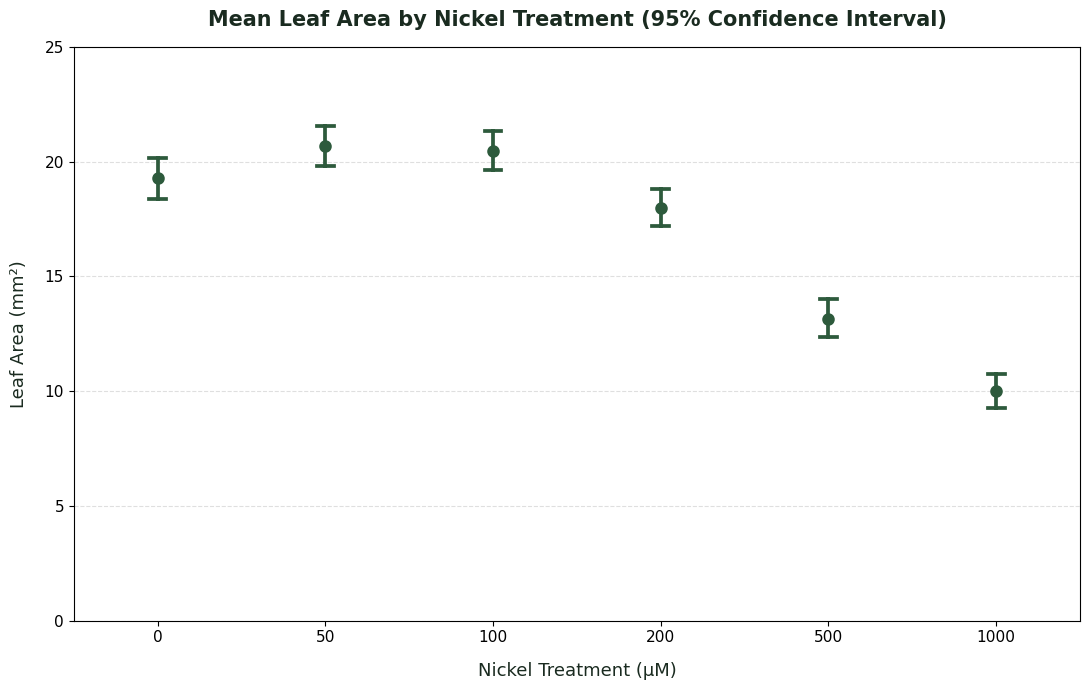

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the design and features datasets
df_design = pd.read_csv('rgb2-design.csv')
df_features = pd.read_csv('rgb2-features.csv')

# 2. Merge datasets on 'sample_key'
df_merged = pd.merge(df_design, df_features[['sample_key', 'area_mm2']], on='sample_key', how='inner')

# Sort treatments numerically
df_merged['treatment'] = pd.Categorical(df_merged['treatment'], categories=sorted(df_merged['treatment'].unique()), ordered=True)

# 3. Create the point plot with fixed parameters
plt.figure(figsize=(11, 7))

# Define presentation color scheme
forest_green = '#2D5A3C'
dark_text = '#1A2B20'

sns.pointplot(
    data=df_merged, 
    x='treatment', 
    y='area_mm2', 
    color=forest_green,
    errorbar=('ci', 95),
    linestyle='none',  
    markers='o',
    markersize=7,
    capsize=0.1
)

# Customize plot labels and formatting
plt.title('Mean Leaf Area by Nickel Treatment (95% Confidence Interval)', fontsize=15, fontweight='bold', pad=15, color=dark_text)
plt.xlabel('Nickel Treatment (µM)', fontsize=13, labelpad=12, color=dark_text)
plt.ylabel('Leaf Area (mm²)', fontsize=13, labelpad=12, color=dark_text)
plt.ylim(0, 25)

# Adjust tick label sizes and add grid
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.4, axis='y')
plt.tight_layout()

# Save and display the plot
plt.savefig('nickel_treatment_pointplot.png', dpi=300)
plt.show()